### Analyse

A faire :
- EDA avec graphiques
    - Histogrammes
    - Boîtes à moustache
    - Histogramme comparé par série
    - Histogramme comparé par plateforme
- Moyenne avec intervalles de confiance
- Ecart-type

In [2]:
import numpy as np 
import pandas as pd
import seaborn as sns

In [3]:
df = pd.read_csv("df_clean.csv")
df

,avis,dates,series,notes,plateforme
0,"Un début de saison (Ép. 01) très réussi, qui t...",2026-02-19,A Knight of the Seven Kingdoms,10.0,Allocine
1,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,10.0,Allocine
2,Quelle drôle d’idée de faire un schema aussi c...,2026-02-24,A Knight of the Seven Kingdoms,7.0,Allocine
3,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,9.0,Allocine
4,Je ne suis probablement pas très objectif conc...,2026-02-08,A Knight of the Seven Kingdoms,8.0,Allocine
...,...,...,...,...,...
1602,Mediocre filmmaking - Weak script in combinati...,2025-10-29,King & Conqueror,1.0,Imdb
1603,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,3.0,Imdb
1604,I get it... -,2026-02-26,King & Conqueror,7.0,Imdb
1605,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,3.0,Imdb


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1607 entries, 0 to 1606
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   avis        1607 non-null   object 
 1   dates       1607 non-null   object 
 2   series      1607 non-null   object 
 3   notes       1607 non-null   float64
 4   plateforme  1607 non-null   object 
dtypes: float64(1), object(4)
memory usage: 62.9+ KB


In [5]:
print(df['series'].value_counts(), '\n')
print(df['series'].value_counts(normalize=True))

# Prépondérance importante de la série 'A knight of the seven kingdoms'

series
A Knight of the Seven Kingdoms    1404
King & Conqueror                   203
Name: count, dtype: int64 

series
A Knight of the Seven Kingdoms    0.873678
King & Conqueror                  0.126322
Name: proportion, dtype: float64


In [6]:
print(df['plateforme'].value_counts(), '\n')
print(df['plateforme'].value_counts(normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme
Imdb        1412
Allocine     195
Name: count, dtype: int64 

plateforme
Imdb        0.878656
Allocine    0.121344
Name: proportion, dtype: float64


In [7]:
display(pd.crosstab(df['series'], df['plateforme']))
print()
display(pd.crosstab(df['series'], df['plateforme'], normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,165,1239
King & Conqueror,30,173


plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,0.102676,0.771002
King & Conqueror,0.018668,0.107654


In [8]:
display(df.describe())
print()
print('Statistiques sur la plateforme Allociné :\n', df[df['plateforme'] == 'Allocine'].describe() )
print()
print('Statistiques sur la plateforme Imdb :\n', df[df['plateforme'] == 'Imdb'].describe())

# Différences importantes de notation entre allociné et imdb : imdb note nettement plus haut 
# Différence de public ou de pays (fr vs usa) ?

,notes
count,1607.000000
mean,7.794648
std,3.041047
min,1.000000
25%,6.000000
50%,9.000000
75%,10.000000
max,10.000000



Statistiques sur la plateforme Allociné :
             notes
count  195.000000
mean     6.620513
std      3.010221
min      1.000000
25%      4.000000
50%      7.000000
75%      9.000000
max     10.000000

Statistiques sur la plateforme Imdb :
              notes
count  1412.000000
mean      7.956799
std       3.010537
min       1.000000
25%       7.000000
50%      10.000000
75%      10.000000
max      10.000000


In [9]:
print('Statistiques sur la série : A knight of the seven kingdoms :\n', df[df['series'] == 'A Knight of the Seven Kingdoms'].describe() )
print()
print('Statistiques sur la série King & Conquerer :\n', df[df['series'] == 'King & Conqueror'].describe())

# Différences importantes de notation entre allociné et imdb : imdb note nettement plus haut 
# Différence de public ou de pays (fr vs usa) ?

Statistiques sur la série : A knight of the seven kingdoms :
              notes
count  1404.000000
mean      8.287749
std       2.727039
min       1.000000
25%       8.000000
50%      10.000000
75%      10.000000
max      10.000000

Statistiques sur la série King & Conquerer :
             notes
count  203.000000
mean     4.384236
std      2.914652
min      1.000000
25%      2.000000
50%      4.000000
75%      7.000000
max     10.000000


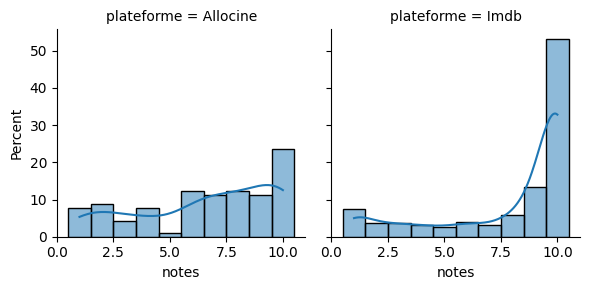

In [10]:
# Visualisons les distributions

g = sns.FacetGrid(df, col="plateforme")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

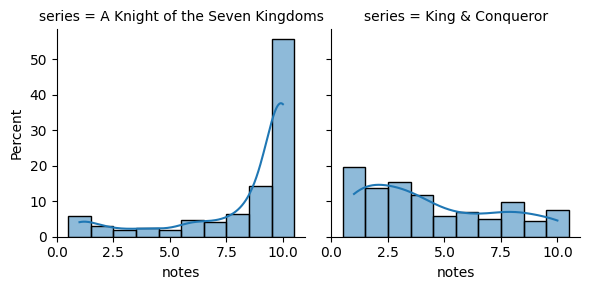

In [11]:
g = sns.FacetGrid(df, col="series")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

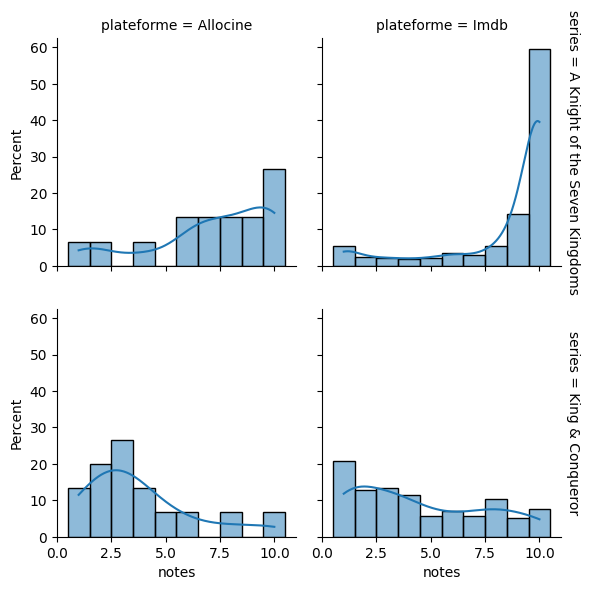

In [12]:
g = sns.FacetGrid(df, col="plateforme", row='series', margin_titles=True)
g.map(sns.histplot, "notes", stat='percent', kde=True, discrete=True);

Pour les deux plateformes, les notes élevées (8 à 10) sont très fortes pour 'A knight of the seven kingdoms' tandis que les notes très faibles (0 à 2) sont plus choisies pour 'King & Conquerer'.

Imdb, plateforme Américaine, a plus de notes positives pour les deux séries. Mais le nombre de 10 pour 'A knight of the seven Kingdom' est impressionant (60%) : la série a été un énorme succès critique.

A l'inverse, Allociné, plateforme française, les notes tendent à être moins positives. C'est particulièrement le cas pour 'King & Conquerer', où les notes entre 0 et 4 sont sureprésentées.

La médiane est révélatrice : elle est de 10 pour Imdb et 7 pour allociné.

annee-mois
202508      87
202509      51
202510      13
202511      21
202512       3
202601     210
202602    1081
202603     141
Name: count, dtype: int64


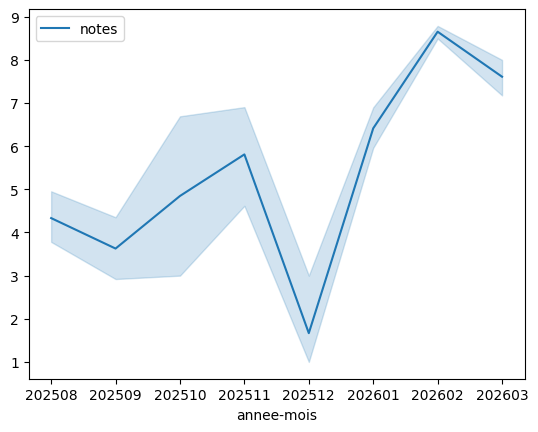

In [ ]:
# Regardons si la date a eu un impact sur les notes données

df['dates'] = pd.to_datetime(df['dates'])

df['annee-mois'] = df['dates'].dt.strftime('%Y%m')
print(df['annee-mois'].value_counts().sort_index())

df_dates = df.set_index('annee-mois').sort_index()

sns.lineplot(data=df_dates.sort_index());